In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
org_df = pd.read_csv("../data/contributions_individuals.csv", dtype=str)

In [ ]:
org_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 335 entries, 0 to 334
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   contributor_name              335 non-null    object
 1   contributor_first_name        4 non-null      object
 2   contributor_last_name         0 non-null      object
 3   contributor_street_1          335 non-null    object
 4   contributor_street_2          92 non-null     object
 5   contributor_city              335 non-null    object
 6   contributor_state             335 non-null    object
 7   contributor_zip               335 non-null    object
 8   contributor_employer          4 non-null      object
 9   contributor_occupation        4 non-null      object
 10  committee_id                  335 non-null    object
 11  committee_name                0 non-null      object
 12  contribution_receipt_date     335 non-null    object
 13  contribution_receipt

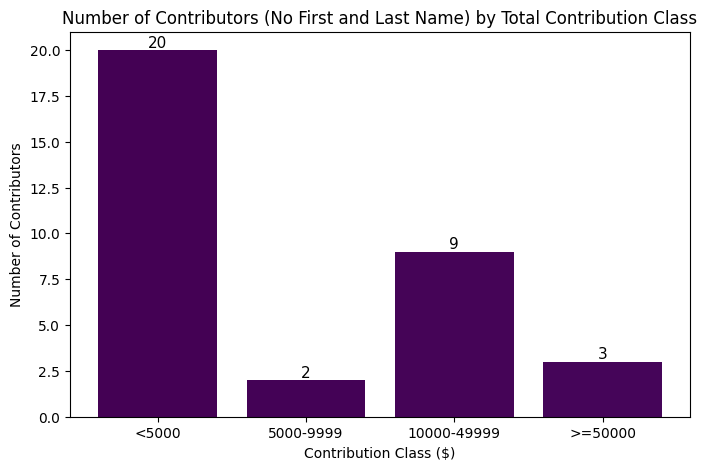

In [ ]:
org_df['contribution_receipt_amount'] = pd.to_numeric(org_df['contribution_receipt_amount'], errors='coerce')

# Group by contributor_name and sum contributions
total_per_contributor = org_df.groupby('contributor_name')['contribution_receipt_amount'].sum().reset_index()

# Define contribution classes
def classify_contribution(amount):
    if amount < 5000:
        return '<5000'
    elif 5000 <= amount < 10000:
        return '5000-9999'
    elif 10000 <= amount < 50000:
        return '10000-49999'
    else:
        return '>=50000'

# Apply classification
total_per_contributor['class'] = total_per_contributor['contribution_receipt_amount'].apply(classify_contribution)

# Define custom category order
class_order = ['<5000', '5000-9999', '10000-49999', '>=50000']
total_per_contributor['class'] = pd.Categorical(total_per_contributor['class'], categories=class_order, ordered=True)

# Count contributors per class
class_counts = total_per_contributor['class'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,5))
bars = plt.bar(class_counts.index, class_counts.values, color=plt.cm.viridis(range(len(class_counts))))

# Add exact numbers on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval , int(yval), ha='center', va='bottom', fontsize=11)

plt.xlabel("Contribution Class ($)")
plt.ylabel("Number of Contributors")
plt.title("Number of Contributors (No First and Last Name) by Total Contribution Class")
plt.show()
